In [2]:
import os
import scanpy as sc
import scvelo as scv
import matplotlib.pyplot as plt

In [ ]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'unzip', 'NB')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'NB')
pth_fig = os.path.join(pth, 'figures', 'neuroblastoma')

In [7]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
adata

AnnData object with n_obs × n_vars = 5101 × 19695
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident', 'celltype'
    uns: 'Phase_colors', 'X_name', 'celltype_colors', 'ident_colors', 'log1p'
    obsm: 'UMAP.GRAPH', 'X_pca', 'X_umap'
    layers: 'logcounts', None (.X)

In [4]:
ldata = sc.read_loom(os.path.join(pth_in, 'ICp-pPDX63-velocyto.loom'))
ldata

AnnData object with n_obs × n_vars = 12209 × 33538
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'matrix', 'ambiguous', 'spliced', 'unspliced', None (.X)

In [8]:
# merge processed + velocyto adata
adata = scv.utils.merge(adata, ldata)
adata.layers['normalized'] = adata.X.copy()
adata.X = adata.layers['matrix'].copy()
adata

AnnData object with n_obs × n_vars = 5101 × 19679
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.RPL', 'percent.RPS', 'S.Score', 'G2M.Score', 'Phase', 'CC.Difference', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'seurat_clusters', 'ident', 'celltype', 'sample_batch', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size'
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    uns: 'Phase_colors', 'X_name', 'celltype_colors', 'ident_colors', 'log1p'
    obsm: 'UMAP.GRAPH', 'X_pca', 'X_umap'
    layers: 'logcounts', None (.X), 'matrix', 'ambiguous', 'spliced', 'unspliced', 'normalized'

In [9]:
scv.pp.filter_and_normalize(adata)
scv.pp.moments(adata)

Normalized count data: X, spliced, unspliced.
computing neighbors


/home/caleb/tmp/ipykernel_1991175/233639239.py:2: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata)
/home/caleb/miniconda3/envs/scvelo/lib/python3.13/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


    finished (0:00:01) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)
computing moments based on connectivities
    finished (0:00:19) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


In [10]:
scv.tl.recover_dynamics(adata, n_top_genes = 2000, n_jobs = 8)

recovering dynamics (using 8/88 cores)
or disable the progress bar using `show_progress_bar=False`.


/home/caleb/miniconda3/envs/scvelo/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=1991175) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


    finished (0:07:11) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)


In [11]:
scv.tl.velocity(adata, mode = 'dynamical')

computing velocities
    finished (0:00:19) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)


In [12]:
scv.tl.velocity_graph(adata)

computing velocity graph (using 1/88 cores)


/home/caleb/miniconda3/envs/scvelo/lib/python3.13/multiprocessing/popen_fork.py:73: DeprecationWarning: This process (pid=1991175) is multi-threaded, use of fork() may lead to deadlocks in the child.
  self.pid = os.fork()


    finished (0:00:43) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


In [13]:
scv.tl.latent_time(adata)

computing terminal states
    identified 1 region of root cells and 1 region of end points .
    finished (0:00:01) --> added
    'root_cells', root cells of Markov diffusion process (adata.obs)
    'end_points', end points of Markov diffusion process (adata.obs)
computing latent time using root_cells as prior
    finished (0:00:06) --> added 
    'latent_time', shared time (adata.obs)


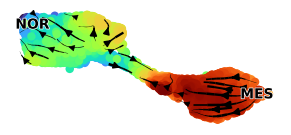

In [ ]:
s = 150
fig, ax = plt.subplots(1, 1, figsize = (3.5, 1.5))
sc.pl.umap(adata, color = 'latent_time', cmap = 'turbo',
           size = s, colorbar_loc = None, frameon = False,
           show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
scv.pl.velocity_embedding_stream(
    adata, basis = 'umap', size = s, alpha = 0,
    density = .6, max_length = .5, show = False,
    ax = ax)
sc.pl.umap(adata, color = 'celltype', size = s, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.invert_xaxis(); ax.set_title('')

pos_dict = {
    'NOR' : (2.5, 1.5),
    'MES' : (-3, 0)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ == 'NOR/MES':
        label.set_text('')
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_fig, 'velocity.pdf')
plt.savefig(fn, bbox_inches = 'tight')

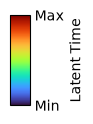

In [11]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Latent Time')
ticks = [adata.obs.latent_time.min(),
         adata.obs.latent_time.max()]
cb.set_ticks(ticks, labels = ['Min', 'Max'])
fn = os.path.join(pth_fig, 'velo_colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')

In [36]:
adata.write(os.path.join(pth_out, 'velocity.h5ad'))